# Stage 11: Success criteria and test design

Before any new research, this notebook checks two things behind `reports/research_protocol.md`:

1. How likely is a real edge to pass our tests, and how likely is a false one?
2. How much return do costs and tax take away?

No market data is used here.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from pmo import research
from pmo.plotting import FIGURES, MUTED, PALETTE, apply_style

apply_style()
DEVELOPMENT, VALIDATION, SEEN = 9.0, 1.83, 3.0
IDEAS = 10

## 1. What a stated edge looks like in a test

The t-statistic of an active return is roughly the information ratio × √years. This shows how long
it takes for a real edge to reach t = 2, and how the hurdle rises as more ideas are tried.

In [2]:
years_needed = pd.Series({ir: (2 / ir) ** 2 for ir in [0.3, 0.5, 0.75, 1.0]},
                         name="years_to_reach_t_2").round(1)
hurdles = pd.Series({n: research.hurdle_t(n) for n in [1, 5, 10, 20, 50]}, name="t_hurdle").round(2)
print(hurdles.to_string())
years_needed.to_frame()

1     1.96
5     2.58
10    2.81
20    3.02
50    3.29


,years_to_reach_t_2
0.30,44.4
0.50,16.0
0.75,7.1
1.00,4.0


## 2. Comparing gate designs

Each design is a development t-statistic hurdle plus requirements on later periods. The first three
columns show how often skill-free ideas pass. The rest show how often a real edge passes.

In [3]:
designs = {
    "t 3.0, later periods positive": [(DEVELOPMENT, 3.0), (VALIDATION, 0), (SEEN, 0)],
    "t 2.5, later periods positive": [(DEVELOPMENT, 2.5), (VALIDATION, 0), (SEEN, 0)],
    "t 2.0, later periods positive": [(DEVELOPMENT, 2.0), (VALIDATION, 0), (SEEN, 0)],
    "t 2.0, validation positive only": [(DEVELOPMENT, 2.0), (VALIDATION, 0)],
    "t 2.0 in development only": [(DEVELOPMENT, 2.0)],
}
rows = {}
for name, gates in designs.items():
    single = research.gate_pass_rate(0, gates)
    row = {"no_skill_1_idea": single,
           "no_skill_10_ideas": research.family_false_positive(single, 10),
           "no_skill_20_ideas": research.family_false_positive(single, 20)}
    row.update({f"IR {ir}": research.gate_pass_rate(ir, gates) for ir in [0.3, 0.5, 0.75, 1.0]})
    rows[name] = row
pd.DataFrame(rows).T.round(3)

,no_skill_1_idea,no_skill_10_ideas,no_skill_20_ideas,IR 0.3,IR 0.5,IR 0.75,IR 1.0
"t 3.0, later periods positive",0.000,0.003,0.007,0.008,0.040,0.173,0.437
"t 2.5, later periods positive",0.002,0.015,0.031,0.025,0.096,0.306,0.604
"t 2.0, later periods positive",0.006,0.055,0.108,0.062,0.187,0.457,0.735
"t 2.0, validation positive only",0.011,0.108,0.205,0.089,0.232,0.506,0.767
t 2.0 in development only,0.023,0.206,0.369,0.136,0.309,0.599,0.841


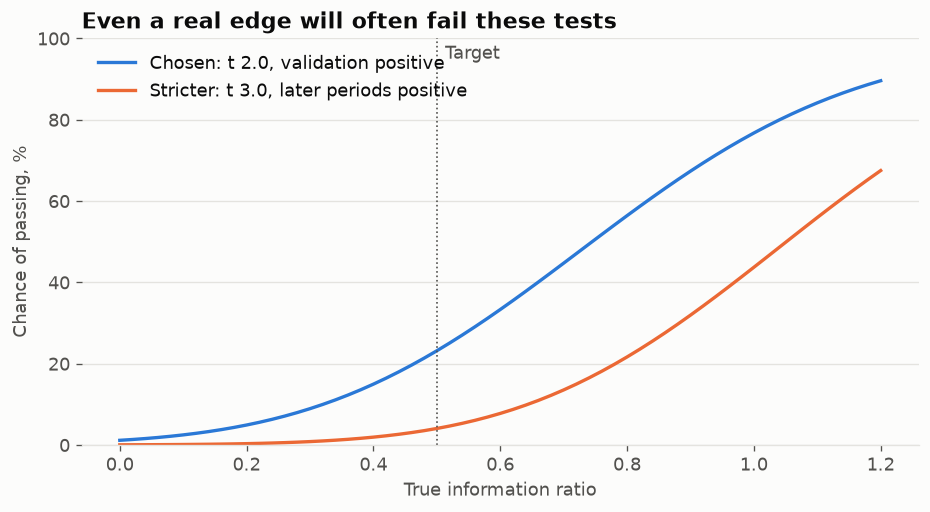

In [4]:
chosen = designs["t 2.0, validation positive only"]
strict = designs["t 3.0, later periods positive"]
ratios = np.linspace(0, 1.2, 61)
fig, ax = plt.subplots(figsize=(9, 4.4))
ax.plot(ratios, [research.gate_pass_rate(r, chosen) * 100 for r in ratios], color=PALETTE[0],
        label="Chosen: t 2.0, validation positive")
ax.plot(ratios, [research.gate_pass_rate(r, strict) * 100 for r in ratios], color=PALETTE[1],
        label="Stricter: t 3.0, later periods positive")
ax.axvline(0.5, color=MUTED, linewidth=1, linestyle=":")
ax.annotate("Target", (0.5, 95), xytext=(5, 0), textcoords="offset points", color=MUTED)
ax.set_ylim(0, 100)
ax.set_xlabel("True information ratio")
ax.set_ylabel("Chance of passing, %")
ax.set_title("Even a real edge will often fail these tests")
ax.legend(frameon=False, loc="upper left")
fig.savefig(FIGURES / "11_gate_power.png")
plt.show()

## 3. The cost budget

One-way turnover of 100% means replacing the whole portfolio once a year. The tax column is a rough
upper figure on a 15% gross return, because an index holder also pays tax eventually, only later.

In [5]:
turnovers = [0.25, 0.5, 1.0, 1.5, 2.0, 4.0]
budget = pd.DataFrame({
    "cost_large_caps": [research.annual_cost(t, 0.0020) for t in turnovers],
    "cost_mid_caps": [research.annual_cost(t, 0.0035) for t in turnovers],
    "cost_stress": [research.annual_cost(t, 0.0070) for t in turnovers],
    "tax": [research.tax_drag(0.15, t) for t in turnovers],
}, index=pd.Index(turnovers, name="one_way_turnover")) * 100
budget["gross_edge_for_3_points_after_cost_and_tax"] = 3 + budget["cost_mid_caps"] + budget["tax"]
budget.round(2)

,cost_large_caps,cost_mid_caps,cost_stress,tax,gross_edge_for_3_points_after_cost_and_tax
one_way_turnover,,,,,
0.25,0.1,0.18,0.35,0.47,3.64
0.50,0.2,0.35,0.70,0.94,4.29
1.00,0.4,0.70,1.40,1.88,5.58
1.50,0.6,1.05,2.10,3.00,7.05
2.00,0.8,1.40,2.80,3.00,7.40
4.00,1.6,2.80,5.60,3.00,8.80


## Conclusions

1. **Three years could never have settled Stage 10.** An information ratio of 0.5 needs 16 years to
   reach t = 2.
2. **Sensible gates will reject many real edges.** That's the price of keeping false ones out, so a
   failure means "not proven", while a pass deserves more trust.
3. **Limiting ideas tried matters as much as the hurdle.** With 10 ideas the false-pass rate is about
   11%. With 20 it almost doubles.
4. **Tax can outweigh trading costs,** and it jumps once holdings drop under a year. Dynamic exits add
   to this, which is why each one has to prove its worth in Stage 16.